In [1]:
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers

df = pd.read_csv('datos/final_dataset_std.csv', sep=';')

vars_ = ['P_ac', 'P_cu', 'T_out', 'T_MEAS', 'T_celCC']
# del más viejo (-7) al más reciente (-0)
X = np.stack(
    [df[[f'{v}-{k}' for k in range(7, -1, -1)]].values for v in vars_],
    axis=2
)                                   # (27013, 8, 5)
y = df['TLHC'].values               # (27013,)
print(X.shape, y.shape)

# split cronológico 80/20, sin shuffle
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = keras.Sequential([
    layers.Input(shape=(8, 5)),
    layers.LSTM(64),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)                 # lineal: regresión
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

hist = model.fit(
    X_train, y_train,
    epochs=30, batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

print(model.evaluate(X_test, y_test))

(27013, 8, 5) (27013,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - loss: 0.1256 - mae: 0.2707 - val_loss: 0.0945 - val_mae: 0.2518
Epoch 2/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 0.0779 - mae: 0.2094 - val_loss: 0.0607 - val_mae: 0.1913
Epoch 3/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 0.0684 - mae: 0.1946 - val_loss: 0.0461 - val_mae: 0.1666
Epoch 4/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0616 - mae: 0.1834 - val_loss: 0.0444 - val_mae: 0.1619
Epoch 5/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 0.0572 - mae: 0.1771 - val_loss: 0.0471 - val_mae: 0.1645
Epoch 6/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0541 - mae: 0.1713 - val_loss: 0.0556 - val_mae: 0.1803
Epoch 7/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - loss: 0.0520 - mae: 0.1679 - val_loss: 0.0460 - val_mae: 0.1681
Epoch 8/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - loss: 0.0502 - mae: 0.1648 - val_loss: 0.0574 - val_mae: 0.1843
Epoch 9/30
304/304 ━━━━━━━━━━━━━━━━━━━━ 9s 24

train: -0.3170929704155458 0.8590548193818047
test:  1.2682545050294647 0.19285517040689068
count    21610.000000
mean        -0.282886
std          0.823142
min         -1.575178
25%         -1.044908
50%         -0.378283
75%          0.258040
max          2.439721
Name: T_out-0, dtype: float64
count    5403.000000
mean        1.131439
std         0.830345
min        -0.969155
25%         0.545901
50%         1.076170
75%         1.757946
max         3.727519
Name: T_out-0, dtype: float64
MSE baseline: 2.5505197346525392
169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


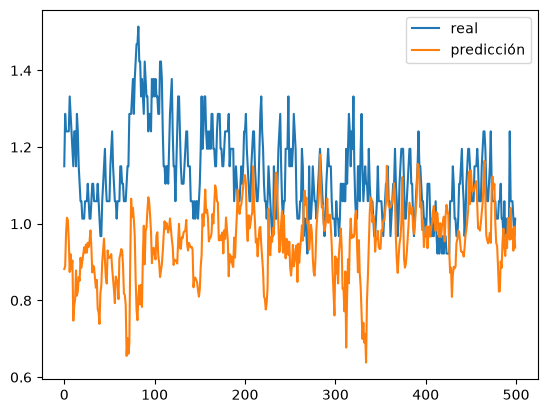

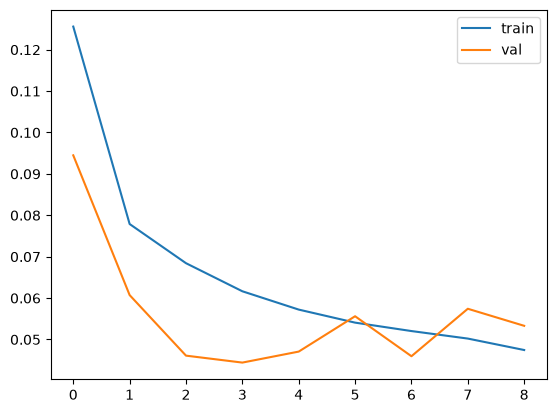

In [2]:
import matplotlib.pyplot as plt

# 1. ¿El test es distinto al train?
print("train:", y_train.mean(), y_train.std())
print("test: ", y_test.mean(), y_test.std())
print(df['T_out-0'].iloc[:split].describe())
print(df['T_out-0'].iloc[split:].describe())


print("MSE baseline:", np.mean((y_test - y_train.mean())**2))

# 3. Real vs predicho
pred = model.predict(X_test).ravel()
plt.plot(y_test[:500], label='real')
plt.plot(pred[:500], label='predicción')
plt.legend(); plt.show()

# 4. Curvas de aprendizaje
plt.plot(hist.history['loss'], label='train')
plt.plot(hist.history['val_loss'], label='val')
plt.legend(); plt.show()

sesgo medio (pred - real): -0.3693793274664888


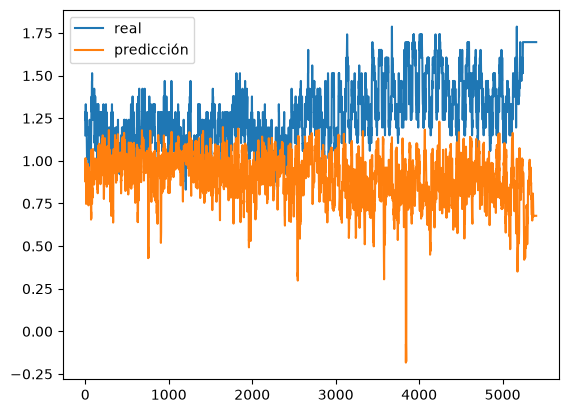

In [3]:
print("sesgo medio (pred - real):", np.mean(pred - y_test))
plt.plot(y_test, label='real'); plt.plot(pred, label='predicción')
plt.legend(); plt.show()

In [1]:
n = len(X)
n_bloques = 10
tam = n // n_bloques
gap = 24

idx_train, idx_test = [], []
for b in range(n_bloques):
    ini = b * tam
    fin = (b + 1) * tam if b < n_bloques - 1 else n
    corte = ini + int(0.8 * (fin - ini))
    idx_train += list(range(ini + gap, corte - gap))
    idx_test  += list(range(corte, fin))

idx_train = np.array(idx_train)
idx_test = np.array(idx_test)

X_train, y_train = X[idx_train], y[idx_train]
X_test,  y_test  = X[idx_test],  y[idx_test]
print(X_train.shape, X_test.shape)

NameError: name 'X' is not defined

(27013, 8, 5) (27013,)
(21123, 8, 5) (5410, 8, 5)
TLHC  train: -0.002   test: 0.010
T_out train: -1.58 a 3.42
T_out test:  -1.27 a 3.73
Epoch 1/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.1241 - mae: 0.2580 - val_loss: 0.2276 - val_mae: 0.4488
Epoch 2/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 0.0703 - mae: 0.1960 - val_loss: 0.2121 - val_mae: 0.4335
Epoch 3/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0612 - mae: 0.1818 - val_loss: 0.1932 - val_mae: 0.4101
Epoch 4/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - loss: 0.0560 - mae: 0.1734 - val_loss: 0.1890 - val_mae: 0.4029
Epoch 5/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - loss: 0.0527 - mae: 0.1678 - val_loss: 0.1891 - val_mae: 0.4021
Epoch 6/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - loss: 0.0499 - mae: 0.1633 - val_loss: 0.1834 - val_mae: 0.3945
Epoch 7/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - loss: 0.0475 - mae: 0.1594 - val_loss: 0.1891 - val_mae: 0.4002
Epoch 8/30
298/298 ━━━━━━━━

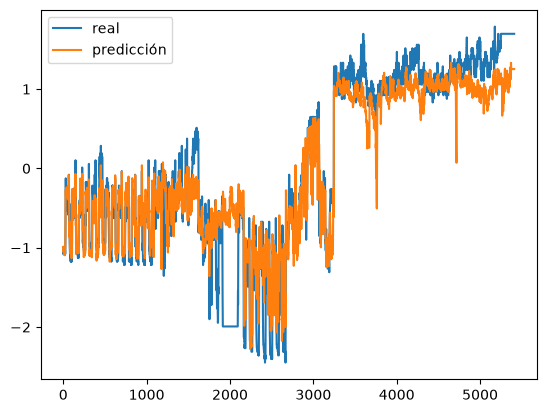

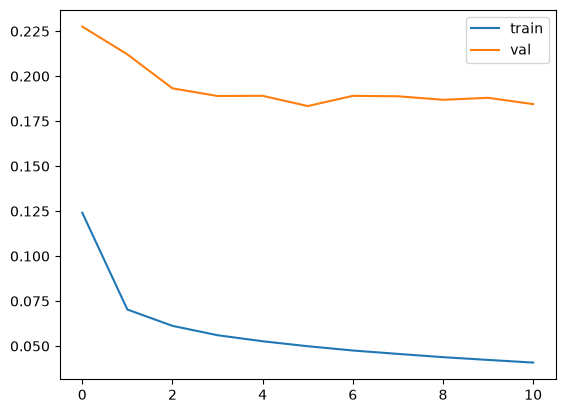

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# 1. Datos
df = pd.read_csv('datos/final_dataset_std.csv', sep=';')
vars_ = ['P_ac', 'P_cu', 'T_out', 'T_MEAS', 'T_celCC']
X = np.stack([df[[f'{v}-{k}' for k in range(7, -1, -1)]].values for v in vars_], axis=2)
y = df['TLHC'].values
print(X.shape, y.shape)

# 2. Split por bloques con hueco
n, n_bloques, gap = len(X), 10, 24
tam = n // n_bloques
idx_train, idx_test = [], []
for b in range(n_bloques):
    ini = b * tam
    fin = (b + 1) * tam if b < n_bloques - 1 else n
    corte = ini + int(0.8 * (fin - ini))
    idx_train += list(range(ini + gap, corte - gap))
    idx_test  += list(range(corte, fin))
idx_train, idx_test = np.array(idx_train), np.array(idx_test)
X_train, y_train = X[idx_train], y[idx_train]
X_test,  y_test  = X[idx_test],  y[idx_test]
print(X_train.shape, X_test.shape)

# 3. Comprobar que ya no hay drift
print("TLHC  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))
t_out = df['T_out-0'].values
print("T_out train: %.2f a %.2f" % (t_out[idx_train].min(), t_out[idx_train].max()))
print("T_out test:  %.2f a %.2f" % (t_out[idx_test].min(), t_out[idx_test].max()))

# 4. Modelo
keras.utils.set_random_seed(0)
model = keras.Sequential([
    layers.Input(shape=(8, 5)),
    layers.LSTM(64),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
hist = model.fit(X_train, y_train, epochs=30, batch_size=64, validation_split=0.1,
                 callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])

# 5. Resultados y rivales
pred = model.predict(X_test).ravel()
A_tr = np.column_stack([np.ones(len(X_train)), X_train.reshape(len(X_train), -1)])
A_te = np.column_stack([np.ones(len(X_test)),  X_test.reshape(len(X_test), -1)])
beta, *_ = np.linalg.lstsq(A_tr, y_train, rcond=None)
pred_lin = A_te @ beta
pred_ing = y[idx_test - 1]

for nombre, p in [('LSTM', pred), ('Lineal', pred_lin), ('Ingenuo', pred_ing)]:
    print(f"{nombre:8s} MSE: {np.mean((y_test - p)**2):.4f}   MAE: {np.mean(np.abs(y_test - p)):.4f}")
print("sesgo LSTM (pred - real):", np.mean(pred - y_test))

# 6. Gráficas
plt.plot(y_test, label='real'); plt.plot(pred, label='predicción'); plt.legend(); plt.show()
plt.plot(hist.history['loss'], label='train'); plt.plot(hist.history['val_loss'], label='val'); plt.legend(); plt.show()

In [4]:
tonto = np.mean((y_test - y_train.mean())**2)
print("MSE tonto:", tonto, " LSTM mejora un %.0f%%" % (100 * (1 - 0.1840 / tonto)))

MSE tonto: 1.2694530034551543 | LSTM mejora un 86%


In [1]:
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers

# --- Datos ---
df = pd.read_csv('datos/final_dataset_std.csv', sep=';')
vars_ = ['P_ac', 'P_cu', 'T_out', 'T_MEAS', 'T_celCC']
X = np.stack([df[[f'{v}-{k}' for k in range(7, -1, -1)]].values for v in vars_], axis=2)
y = df['TLHC'].values

# --- Sexta variable: TLHC de los 8 pasos ANTERIORES (t-8 ... t-1) ---
lags = np.stack([np.roll(y, 1 + k) for k in range(7, -1, -1)], axis=1)   # (27013, 8)
X6 = np.concatenate([X, lags[:, :, None]], axis=2)                        # (27013, 8, 6)

# --- Split por bloques 70/10/20 con hueco ---
n, n_bloques, gap = len(X), 10, 24
tam = n // n_bloques
idx_train, idx_val, idx_test = [], [], []
for b in range(n_bloques):
    ini = b * tam
    fin = (b + 1) * tam if b < n_bloques - 1 else n
    largo = fin - ini
    c1 = ini + int(0.7 * largo)
    c2 = ini + int(0.8 * largo)
    idx_train += list(range(ini + gap, c1 - gap))
    idx_val   += list(range(c1, c2 - gap))
    idx_test  += list(range(c2, fin))
idx_train, idx_val, idx_test = map(np.array, (idx_train, idx_val, idx_test))

# --- Comprobación anti-trampa ---
t = idx_test[0]
assert np.allclose(X6[t, :, 5], y[t-8:t]), "El historial no coincide con t-8..t-1"
print("Comprobación OK: la sexta variable solo contiene TLHC de t-8 a t-1")
print(X6.shape, len(idx_train), len(idx_val), len(idx_test))

# --- Función para entrenar y evaluar ---
def correr(Xdatos, n_vars, semilla=0):
    keras.utils.set_random_seed(semilla)
    m = keras.Sequential([layers.Input(shape=(8, n_vars)), layers.LSTM(64),
                          layers.Dense(32, activation='relu'), layers.Dense(1)])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])
    m.fit(Xdatos[idx_train], y[idx_train], epochs=30, batch_size=64,
          validation_data=(Xdatos[idx_val], y[idx_val]), verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m.predict(Xdatos[idx_test], verbose=0).ravel()

# --- Comparación con 3 semillas ---
yt = y[idx_test]
mse = lambda p: np.mean((yt - p)**2)
mae = lambda p: np.mean(np.abs(yt - p))
res = {'5 variables': [], '6 variables (+TLHC)': []}
for s in range(3):
    res['5 variables'].append(correr(X, 5, s))
    res['6 variables (+TLHC)'].append(correr(X6, 6, s))

for nombre, preds in res.items():
    ms = [mse(p) for p in preds]; ma = [mae(p) for p in preds]
    print(f"{nombre:20s} MSE {np.mean(ms):.4f} ± {np.std(ms):.4f} | MAE {np.mean(ma):.4f} ± {np.std(ma):.4f}")

p_ing = y[idx_test - 1]
print(f"{'Ingenuo':20s} MSE {mse(p_ing):.4f} | MAE {mae(p_ing):.4f}")

Comprobación OK: la sexta variable solo contiene TLHC de t-8 a t-1
(27013, 8, 6) 18422 2461 5410
5 variables          MSE 0.1587 ± 0.0158 | MAE 0.2478 ± 0.0086
6 variables (+TLHC)  MSE 0.0064 ± 0.0002 | MAE 0.0578 ± 0.0014
Ingenuo              MSE 0.0098 | MAE 0.0639


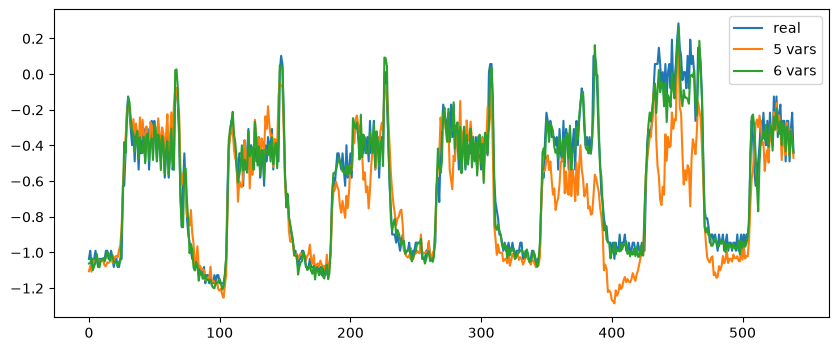

In [2]:
import matplotlib.pyplot as plt; plt.figure(figsize=(10,4)); plt.plot(yt[:540], label='real'); plt.plot(res['5 variables'][0][:540], label='5 vars'); plt.plot(res['6 variables (+TLHC)'][0][:540], label='6 vars'); plt.legend(); plt.show()